## Makemore - MLP Model

In [21]:
import random
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

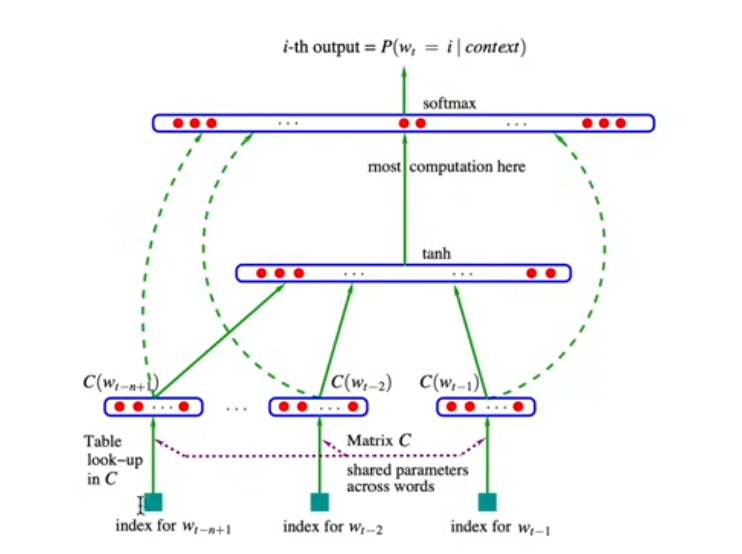

In [2]:
words = open('names.txt', 'r').read().splitlines()

In [3]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}


In [4]:
block_size = 3
x, y = [], []

for w in words:
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        x.append(context)
        y.append(ix)
        context = context[1:] + [ix]

X = torch.tensor(x)
Y = torch.tensor(y)

In [ ]:
def build_datset(words):
    block_size = 3
    x, y = [], []

    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            x.append(context)
            y.append(ix)
            context = context[1:] + [ix]

    X = torch.tensor(x)
    Y = torch.tensor(y)
    return X, Y

random.seed(42)
random.shuffle(words)
n1 = (0.8 * len(words))
n2 = (0.9 * len(words))

Xtr, Ytr = build_datset(words[:n1])
Xdev, Ydev = build_datset(words[n1:n2])
Xte, Yte = build_datset(words[n2:])

In [5]:
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

### Look Up Table

In [ ]:
C = torch.randn((27, 4))
emb = C[X]

Following perform exactly same task. for multiplying input with weights we have to compliment their dimensions for matrix multiplication to be possible. The emb matrix has shape: (32,3,2) and weight matrix shape is (6,100) so we use one of the below method to convert shape of wmb matrix to (32,6).
- torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1)
- torch.cat(torch.unbind(emb, 1), 1)
- emb.view(32, 6)

### Hidden Layer Implementation

In [ ]:
W1 = torch.randn((12, 100), requires_grad=True)
b1 = torch.randn(100)
h = torch.tanh(emb.view(emb.shape[0], 12) @ W1 + b1)  #shape: 32,100

### Output Layer Implementation

In [ ]:
W2 = torch.randn((100, 27), requires_grad=True)
b2 = torch.randn(27)
logits = h @ W2 + b2
# --softmax--
# counts = logits.exp()
# probs = counts / counts.sum(1, keepdim=True)
# # --Loss--
# loss = -probs[torch.arange(32), Y].log().mean()
loss = F.cross_entropy(logits, Y) 
loss

- F.cross_entropy() makes calculation easy and gives loss. No need to evaluate counts, probs. Less memory is used as python creates new tensors for counts and probs and also backpropagation is much easier.
- cross_entropy handles vlaues more efficently as consider a  value on logits is 100 that would make the corresponding value on counts tensor infinit

### Complete Implementation

In [16]:
# parameters
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 4), generator=g, requires_grad=True)
W1 = torch.randn((12, 100), generator=g, requires_grad=True)
b1 = torch.randn(100, generator=g, requires_grad=True)
W2 = torch.randn((100, 27), generator=g, requires_grad=True)
b2 = torch.randn(27, generator=g, requires_grad=True)
parameters = [C, W1, b1, W2, b2]

In [ ]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [ ]:
lri = []
stepi = []
lossi = []

for i in range(100):
    # mini batches
    ix = torch.randn(0, X.shape[0], (32,))

    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 12) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad

    # Track stats
    lri.append[lre[i]]
    stepi.append(i)
    lossi.append[loss.item()]

print(loss.items())

- iterations take a lot of time cause of input size, performing forward, backward and update takes time.
- so what is done in actual is we do mini batching where we perform forward backward and update on randomly selected batches of input.

In [ ]:
plt.plot(lri, lossi)

- Splitting data into Train, Test and Validation set to ensure that modle doesn't overfit on training data and we can sample from it.
- Training Set -> to train parameters
- Validation Set -> to train hyper parameters (hidden layer)
- Test Set -> evaluate model

In [ ]:
emb = C[Xdev[ix]]
h = torch.tanh(emb.view(-1, 12) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev[ix])
loss

In [ ]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

### Sampling from model

In [ ]:
g = torch.Generator().manual_seed(2147483647)

for _ in range(20):
    out = []
    context = [0] * block_size

    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(-1, 12) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)

        ix = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).items()
        context = context[1:] + ix
        out.append(ix)
        if ix==0:
            break

    print(''.join(itos[i] for i in out))